In [5]:
import numpy as np
import random
import heapq, math
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx

In [6]:
def generate_random_graph(num_vertices = 7, num_edges = 17, min_weight=1.0, max_weight=20.0, directed=False):
    edges = set()
    pairs = set()
    
    while len(edges) < num_edges:
        u = random.randint(1, num_vertices)
        v = random.randint(1, num_vertices)
        
        if u == v:
            continue
 
        if {u, v} == {1, 7}:
            continue
        
        if not directed and (v, u) in edges:
            continue

        pair = (u, v) if directed else (min(u, v), max(u, v))
        if pair in pairs:
            continue
        pairs.add(pair)

        weight = random.uniform(min_weight, max_weight)
        edges.add((u, v, weight))
    
    return list(edges)
g1 = generate_random_graph(7, 17, min_weight=1.0, max_weight=20.0, directed=False)
display(g1)



[(3, 5, 17.14601679034036),
 (3, 1, 14.751445543152498),
 (5, 6, 9.925518972280948),
 (1, 4, 9.454473240896315),
 (7, 6, 6.565970521628006),
 (4, 5, 2.450248711264426),
 (4, 6, 15.255029301444342),
 (3, 4, 11.353270552466748),
 (3, 7, 11.072638362110775),
 (5, 2, 16.026200391361325),
 (3, 2, 2.8441574687864932),
 (6, 2, 17.041832270806665),
 (7, 5, 3.952969475395251),
 (7, 4, 13.799196662878764),
 (1, 2, 2.4401292849174006),
 (6, 1, 13.247437003547448),
 (2, 4, 11.27455791863896)]

In [7]:
def dijkstra(edges, start=1, end=7):
    graph = defaultdict(list)
    for u, v, w in edges:
        graph[u].append((v, w))
        graph[v].append((u, w))  # Undirected graph

    distances = {start: 0}
    previous = {start: None}
    queue = [(0, start)]

    while queue:
        current_distance, current_vertex = heapq.heappop(queue)

        if current_distance > distances.get(current_vertex, float("inf")):
            continue

        if current_vertex == end:
            break

        for neighbor, weight in graph[current_vertex]:
            distance = current_distance + weight
            if distance < distances.get(neighbor, float("inf")):
                distances[neighbor] = distance
                previous[neighbor] = current_vertex
                heapq.heappush(queue, (distance, neighbor))

    if end not in distances:
        return [], float("inf")

    path = []
    current_vertex = end
    while current_vertex is not None:
        path.append(current_vertex)
        current_vertex = previous[current_vertex]

    path.reverse()
    return path, distances[end]

print("Dijkstra's Algorithm:", dijkstra(g1, start=1, end=7))


Dijkstra's Algorithm: ([1, 4, 5, 7], 15.857691427555991)


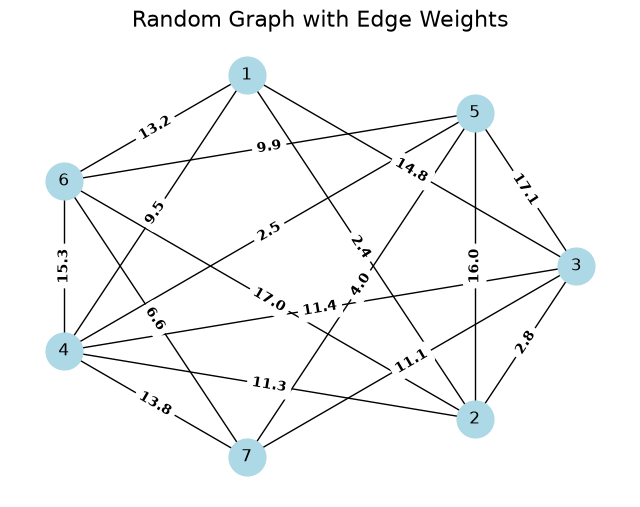

In [9]:
G = nx.Graph()
for u, v, w in g1:
    G.add_edge(u, v, weight=w)

pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(8, 6))

nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=700, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
nx.draw_networkx_edges(G, pos, ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{w:.1f}" for u, v, w in g1}, font_size=10, font_weight='bold', ax=ax)

ax.set_title("Random Graph with Edge Weights", fontsize=16)
ax.axis('off')

plt.show()